# NFL Predictor v1: Straight-Up Picks

James Havrilla III, October 2026

This notebook predicts the winner of NFL games using only team and game data. I left betting lines out on purpose, both as model inputs and as benchmarks, so the result shows what on-field data can do by itself.

I followed the project checklist in Aurélien Géron's *Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow* (Chapter 2 and Appendix B), and the notebook follows its eight steps:

1. Frame the problem
2. Get the data
3. Explore the data
4. Prepare the data
5. Shortlist models
6. Fine-tune and evaluate once on the holdout
7. Present the results
8. Launch, monitor and maintain

The final ensemble picked 63.2% of games in the 2023 to 2025 holdout (95% CI 60.0% to 66.5%), statistically tied with a plain Elo rating (64.1%) and well ahead of always picking the home team (54.9%).

## 1. Frame the problem

The goal is to pick the winner of each game before kickoff. I treat it as supervised binary classification, where the target is whether the home team wins, and retrain the model in batch each week.

Accuracy is the main metric because the output is a pick. I also track log loss and Brier score, which show whether the predicted probabilities can be trusted. To be worth using, the model has to beat two simple baselines on the holdout: always picking the home team, and a plain Elo rating.

In [1]:
import warnings
warnings.filterwarnings('ignore')

import os

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from nflv1 import data, evaluation as ev, features, models

pd.set_option('display.width', 120)

# Download the nflverse data if it isn't here yet. Set to True to force a refresh.
REFRESH = not os.path.exists('data/raw/games.csv')
if REFRESH:
    data.fetch_data('data')

## 2. Get the data

The data comes from nflverse: the game schedule (games.csv) and weekly team stats from 1999 through 2026. The loader drops every betting column as soon as the schedule is read and checks that none remain.

I split by season before exploring anything: 1999 to 2022 for training, 2023 to 2025 as the holdout, and 2026 for live monitoring. A random split would let the model train on games played after the ones it is tested on.

In [2]:
games = data.load_games('data')
team_games = data.load_team_games('data')
features.register(games, team_games)

assert not set(data.BETTING_COLS) & set(games.columns)
print(f'{len(games):,} scheduled games, {int(games.played.sum()):,} played')
games.groupby('season').played.sum().tail()

7,548 scheduled games, 7,383 played


season
2022    284
2023    285
2024    285
2025    285
2026    107
Name: played, dtype: int64

## 3. Explore the data

Everything in this section uses the training seasons only. Two things stood out: home-field advantage has shrunk, especially from 2019 to 2021, and nearly a quarter of games are decided by three points or fewer.

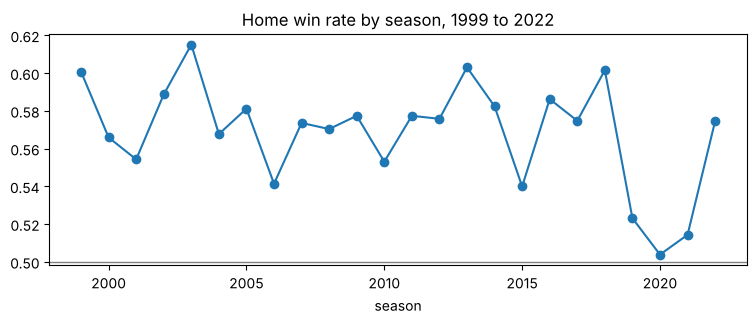

Share of games decided by 3 points or fewer: 0.231


In [3]:
train_games = games[games.played & ~games.tie & games.season.isin(data.TRAIN_SEASONS)]
home_rate = train_games[train_games.neutral == 0].groupby('season').home_win.mean()

ax = home_rate.plot(marker='o', figsize=(9, 3), title='Home win rate by season, 1999 to 2022')
ax.axhline(0.5, color='grey', lw=1)
plt.show()

print('Share of games decided by 3 points or fewer:', round((train_games.result.abs() <= 3).mean(), 3))

In [4]:
F = features.GameFeatures().transform(train_games[['game_id']])
F.index = train_games.index
F.corrwith(train_games.home_win).sort_values()

pts_against_diff       -0.198348
sack_rate_diff         -0.145243
def_pass_epa_db_diff   -0.141005
def_epa_play_diff      -0.134626
home_qb_change         -0.086499
neutral                -0.041142
pen_yds_diff           -0.033346
div_game               -0.025195
season_games            0.010989
playoff                 0.018984
rest_diff               0.025059
away_qb_change          0.062475
def_sack_rate_diff      0.085133
rush_epa_car_diff       0.128396
to_margin_diff          0.170208
pass_epa_db_diff        0.254091
off_epa_play_diff       0.258577
pts_for_diff            0.276775
elo_diff                0.318981
elo_prob                0.320388
dtype: float64

## 4. Prepare the data

`GameFeatures` builds 20 home-minus-away features from games played before kickoff: Elo ratings, exponentially weighted form (EPA, points, sacks, turnovers) and game context (rest, division, site, quarterback change). Its Elo and form settings are hyperparameters, so the search in step 6 tunes them along with the model.

To check for leakage, I change the result of one 2015 game and rebuild the features. Nothing for that game or any earlier game should change.

In [5]:
gid = games[games.season == 2015].game_id.iloc[100]
altered = games.copy()
i = altered.index[altered.game_id == gid][0]
altered.loc[i, ['home_score', 'away_score', 'result']] = [99, 0, 99]
features.register(altered, team_games, 'leak_test')

before = features.GameFeatures().transform(games[['game_id']])
after = features.GameFeatures(source='leak_test').transform(games[['game_id']])
changed = (before.fillna(-9) != after.fillna(-9)).any(axis=1).to_numpy()
pos = list(before.index).index(gid)

print('Games changed up to and including the altered game:', changed[:pos + 1].sum())
print('Games changed after it:', changed[pos + 1:].sum())
assert changed[:pos + 1].sum() == 0

Games changed up to and including the altered game: 0
Games changed after it: 3153


## 5. Shortlist models

I use walk-forward cross-validation: each fold trains on every season before *s* and tests on season *s*, for 2011 through 2022. Géron's examples shuffle the folds, which would leak future games into training here.

On default settings, every learned model lands within about a point of plain Elo.

In [6]:
X, y = ev.modeling_frame(games, data.TRAIN_SEASONS)

rows = []
for name, model in models.shortlist_candidates().items():
    rows.append({'model': name, **ev.cv_evaluate(model, X, y)})

shortlist = pd.DataFrame(rows).sort_values('log_loss')
shortlist[['model', 'accuracy', 'accuracy_std', 'log_loss', 'brier', 'seconds']].round(4)

,model,accuracy,accuracy_std,log_loss,brier,seconds
2,logistic,0.6504,0.0226,0.6254,0.2180,1.1
1,elo_only,0.6491,0.0249,0.6280,0.2193,0.1
4,knn,0.6452,0.0268,0.6295,0.2199,1.2
7,extra_trees,0.6457,0.0228,0.6315,0.2209,16.7
6,random_forest,0.6392,0.0270,0.6341,0.2220,32.6
5,svc_rbf,0.6461,0.0279,0.6408,0.2245,29.9
8,hist_gb,0.6259,0.0233,0.6594,0.2316,3.8
0,always_home,0.5599,0.0304,0.6862,0.2465,0.1
3,naive_bayes,0.6509,0.0247,1.2515,0.2743,0.9


## 6. Fine-tune and evaluate once

`tune.py` runs a randomized search over model and feature settings for logistic regression, gradient boosting and Extra-Trees, selecting on walk-forward log loss. `train_final.py` then applies a rule I set before looking at the holdout: take the candidate with the lowest cross-validated log loss (the three tuned models or their soft-voting ensemble), retrain it on 2001 to 2022, and score it once on 2023 to 2025.

Rerunning both takes about 15 minutes. Set `RUN_SEARCH = True` to do so; otherwise the cells below load the saved results.

In [7]:
RUN_SEARCH = False
if RUN_SEARCH:
    %run tune.py
    %run train_final.py

pd.read_csv('results/final_cv.csv')[['model', 'accuracy', 'accuracy_std', 'log_loss', 'brier']].round(4)

,model,accuracy,accuracy_std,log_loss,brier
0,soft_vote,0.6547,0.0210,0.6245,0.2177
1,logistic,0.6536,0.0205,0.6250,0.2177
2,extra_trees,0.6413,0.0190,0.6267,0.2189
3,hist_gb,0.6469,0.0204,0.6301,0.2200


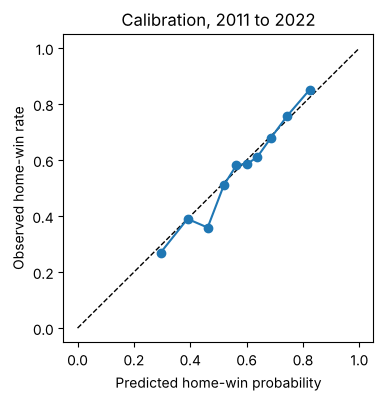

In [8]:
cal = pd.read_csv('results/calibration_cv.csv')
plt.figure(figsize=(4, 4))
plt.plot([0, 1], [0, 1], 'k--', lw=1)
plt.plot(cal.mean_predicted, cal.observed_home_win, 'o-')
plt.xlabel('Predicted home-win probability')
plt.ylabel('Observed home-win rate')
plt.title('Calibration, 2011 to 2022')
plt.show()

In [9]:
print('Holdout, 2023 to 2025 (evaluated once)')
display(pd.read_csv('results/holdout.csv').round(4))
display(pd.read_csv('results/holdout_by_season.csv').round(4))

Holdout, 2023 to 2025 (evaluated once)


,model,n,accuracy,acc_ci_low,acc_ci_high,log_loss,brier
0,final_soft_vote,854,0.6323,0.5999,0.6647,0.6288,0.2197
1,always_home,854,0.5492,0.5157,0.5826,0.6888,0.2478
2,elo_only,854,0.6405,0.6083,0.6728,0.6351,0.2221


,season,mean,count
0,2023,0.6070,285
1,2024,0.6667,285
2,2025,0.6232,284


## 7. Results

The ensemble matched Elo on picks (63.2% against 64.1%, a difference well inside the margin of error) and produced slightly better probabilities (log loss 0.629 against 0.635). The two models disagreed on only 71 of 854 holdout games.

My read is that with mostly team-level inputs, a well-tuned rating system already captures nearly all of the signal. The clearest gains for v2 should come from better inputs rather than more complex models: individual quarterback ratings, a home-field advantage that changes over time, and pre-game injury reports.

The full write-up is in the project report. Every run is recorded in `results/experiments.csv`.

In [10]:
log = pd.read_csv('results/experiments.csv')
log.groupby('stage').size()

stage
final_cv       4
holdout        3
shortlist      9
tune         120
dtype: int64

## 8. Launch, monitor and maintain

Each week I run `python predict_week.py`. It refreshes the data, retrains on every completed game, writes the week's picks to `predictions/` and scores earlier picks against final results.

In [11]:
bundle = joblib.load('models/nfl_v1_final.joblib')
print(bundle['version'], '| selected model:', bundle['selected'])
print('Holdout accuracy:', round(bundle['holdout']['accuracy'], 4))
print('2026 to date:', {k: round(v, 4) for k, v in bundle['live_2026'].items()})

v1.0 | selected model: soft_vote
Holdout accuracy: 0.6323
2026 to date: {'n': 106, 'accuracy': np.float64(0.5755), 'acc_ci_low': np.float64(0.4798), 'acc_ci_high': np.float64(0.6711), 'log_loss': 0.6634, 'brier': 0.2367}
